## This script calculate the topic similarity between international and non-international collaborated papers for **single authors**

In [1]:
import pandas as pd
import numpy as np
import itertools
from multiprocessing import Pool
from tqdm import tqdm
from scipy.spatial import distance
import random
import math
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
embedding_path = "/gpfs/slate-sciencegenome/Embeddings/Data/wos_embedding_specter_all.npz"

In [3]:
embedding_file = np.load(embedding_path)
embedding = embedding_file['emb']
uids = embedding_file['uids']

In [4]:
pub_all_path = "../../data/dropbox/LaborDivision/data/deriveddata/all/pub_author.csv"
pub_all = pd.read_csv(pub_all_path)
pub_all = pub_all.drop(columns=['seqno','lastname','num_author'])

In [5]:
uid_path = "../../data/dropbox/LaborDivision/data/cleanedraw/ostbk_uid.pkl"
uid_df = pd.read_pickle(uid_path)

In [6]:
pub_all['ost_bk'] = pub_all['ost_bk'].astype('str')
pub_all['uid'] = pub_all['ost_bk'].map(uid_df)

In [7]:
len(uids)

84162157

In [8]:
len(embedding)

84162157

### create an dict which records uid and the index in uids array to derive the embedding from the embedding array

In [9]:
uid_index_dict={}
n = 0
for uid in tqdm(uids):
    uid_index_dict[uid]=n
    n=n+1

100%|███████████████████████████| 84162157/84162157 [01:40<00:00, 841606.36it/s]


In [10]:
pub_all.head()

,ost_bk,cluster_id,cntry,role,year,dis,title,alpha,intl,uid
0,29768068,40806321.0,CAN,F,2008,56,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022
1,29768068,41639269.0,CAN,M,2008,56,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022
2,29768068,53722752.0,CAN,L,2008,56,Cyclical and dose-dependent responses of adult...,noalp,0,WOS:000259648000022
3,29768070,65683243.0,JPN,F,2008,51,Biphasic effects of orexin-A on autonomic nerv...,noalp,1,WOS:000260516300012
4,29768070,79129017.0,JPN,M,2008,51,Biphasic effects of orexin-A on autonomic nerv...,noalp,1,WOS:000260516300012


### create a dict to record publications at country-discipline level with distinguish whether international or national

In [11]:
cntry_dis_pubs = pub_all[['cntry','dis','intl','uid']].drop_duplicates()

In [12]:
cntry_dis_dict = {}
cntry_dis_pubs_array = cntry_dis_pubs[['cntry','dis','intl','uid']].values
# Iterate through the dataframe rows
for row in tqdm(cntry_dis_pubs_array):
    cntry = row[0]
    dis = row[1]
    intl = row[2]
    uid = row[3]
    
    # Check if the key_A already exists in the nested dictionary
    if (cntry,dis) in cntry_dis_dict:
        # Check if the key_B already exists for the key_A
        if intl in cntry_dis_dict[(cntry,dis)]:
            # Append the value_C to the existing list
            cntry_dis_dict[(cntry,dis)][intl].append(uid)
        else:
            # Create a new key_B entry with a list containing value_C
            cntry_dis_dict[(cntry,dis)][intl] = [uid]
    else:
        # Create a new key_A entry with a nested dictionary containing key_B and value_C
        cntry_dis_dict[(cntry,dis)] = {intl: [uid]}

100%|███████████████████████████| 21863524/21863524 [00:31<00:00, 686875.15it/s]


In [13]:
def return_embeddings(pubs,uid_index_dict,embedding):
    embed_index = []
    for pub in pubs:
        if pub in uid_index_dict:
            embed_index.append(uid_index_dict[pub])
    if len(embed_index)>0:
        embed_mean = np.mean(embedding[embed_index], axis=0)
        return embed_mean
    else:
        return np.zeros(64)

In [14]:
def cal_angle_dist(v1,v2):
    def dotproduct(v1, v2):
        return sum((a*b) for a, b in zip(v1, v2))
    
    def length(v):
        return math.sqrt(dotproduct(v, v))
    try:
        return math.acos(dotproduct(v1, v2) / (length(v1) * length(v2)))
    except ValueError:
        return np.zeros(64)

In [15]:
cntry_dis_similarity_res = []
for cntry_dis in tqdm(cntry_dis_dict.keys()):
    if 0 in cntry_dis_dict[cntry_dis] and 1 in cntry_dis_dict[cntry_dis]:
        dome_pub = cntry_dis_dict[cntry_dis][0]
        intl_pub = cntry_dis_dict[cntry_dis][1]
        
        dome_embeddings = return_embeddings(dome_pub, uid_index_dict,embedding)
        intl_embeddings = return_embeddings(intl_pub, uid_index_dict, embedding)
        
        if not np.all(dome_embeddings==0) and not np.all(intl_embeddings==0):
            cosine_dist = 1-distance.cosine(dome_embeddings, intl_embeddings)
            angle_dist = cal_angle_dist(dome_embeddings, intl_embeddings)
            
            cntry_dis_similarity_res.append([cntry_dis[0],cntry_dis[1], cosine_dist, "cosine"])
            #cntry_dis_similarity_res.append([cntry_dis[0],cntry_dis[1], angle_dist, 'angular'])

100%|████████████████████████████████████| 21259/21259 [00:42<00:00, 499.05it/s]


In [16]:
cntry_dis_simi = pd.DataFrame(cntry_dis_similarity_res, columns=['cntry','dis','similarity','type'])
cntry_dis_simi.head()

,cntry,dis,similarity,type
0,CAN,56,0.994924,cosine
1,JPN,51,0.974354,cosine
2,CHN,51,0.983185,cosine
3,RUS,27,0.972395,cosine
4,RUS,28,0.991410,cosine


In [17]:
cntry_dis_simi = cntry_dis_simi[cntry_dis_simi.similarity!='invalid angular']

In [18]:
cntry_dis_simi.head(2)

,cntry,dis,similarity,type
0,CAN,56,0.994924,cosine
1,JPN,51,0.974354,cosine


In [19]:
cntry_simi = cntry_dis_simi.groupby(['cntry','type'])['similarity'].mean().reset_index()

In [20]:
stgroup_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_group_meta.csv'
stgroup_df=pd.read_csv(stgroup_path)[['Code','ST']].drop_duplicates()
stgroup_df=stgroup_df.replace(to_replace={'ST':{'Others':'Lagging'}})
stgroup_df.head()

,Code,ST
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [21]:
color_scheme_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/color_scheme.csv'
color_scheme = pd.read_csv(color_scheme_path)
color_scheme = color_scheme[color_scheme['type']=='st']
color_dict = dict(zip(color_scheme['class'], color_scheme['color']))

In [23]:
cntry_simi = cntry_simi.merge(stgroup_df, left_on='cntry', right_on='Code')

In [24]:
cntry_simi.head()

,cntry,type,similarity,Code,ST
0,AFG,cosine,0.830219,AFG,Lagging
1,AGO,cosine,0.843201,AGO,Lagging
2,ALB,cosine,0.814250,ALB,Lagging
3,AND,cosine,0.791784,AND,Lagging
4,ARE,cosine,0.948181,ARE,Lagging


/tmp/ipykernel_263034/1453139846.py:2: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(x='ST',y='similarity',data=cntry_simi[cntry_simi['type']=='cosine'],ax=ax, order=color_dict.keys(), palette=color_dict)


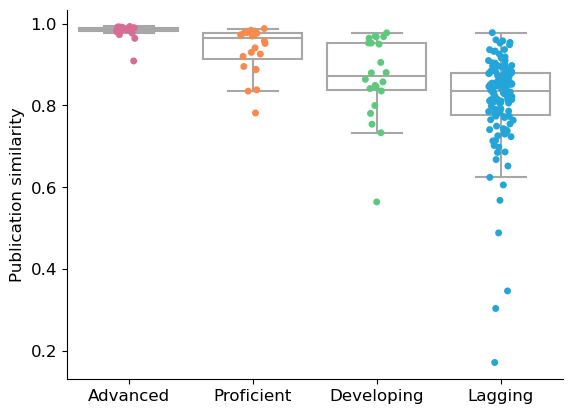

In [25]:
fig, ax=plt.subplots()
sns.stripplot(x='ST',y='similarity',data=cntry_simi[cntry_simi['type']=='cosine'],ax=ax, order=color_dict.keys(), palette=color_dict)
sns.boxplot(x='ST',y='similarity',data=cntry_simi[cntry_simi['type']=='cosine'],
            boxprops={'facecolor':'none', 'edgecolor':'#A7A7A7'},
            medianprops={'color':'#A7A7A7'},
            whiskerprops={'color':'#A7A7A7'},
            capprops={'color':'#A7A7A7'},
            order=color_dict.keys(),
            fliersize=0,
            ax=ax)
ax.set_ylabel("Publication similarity", fontsize=12)
ax.set_xlabel("")
ax.tick_params(axis='both', which='major', labelsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.savefig("../../data/dropbox/LaborDivision/figs/pub_similarity_derived_cntry_dis.pdf",bbox_inches='tight')

In [33]:
cntry_simi = cntry_simi[cntry_simi.type=='cosine']
sts = cntry_simi.ST.unique()
sample_size = cntry_simi[cntry_simi.ST=='Advanced'].shape[0]
bootstrapping_res = []

for st in sts:
    for i in range(20):
        df = cntry_simi[cntry_simi.ST==st]
        df_sampled = df.sample(n=sample_size, replace=True)
        similarity_sampled = df_sampled['similarity'].mean()
        bootstrapping_res.append([similarity_sampled, st])
                          

In [34]:
btsp_res = pd.DataFrame(bootstrapping_res, columns=['simi','st'])

/tmp/ipykernel_918078/1670876550.py:4: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(x='st',y='simi',data=btsp_res,ax=ax, order=order, palette=color)


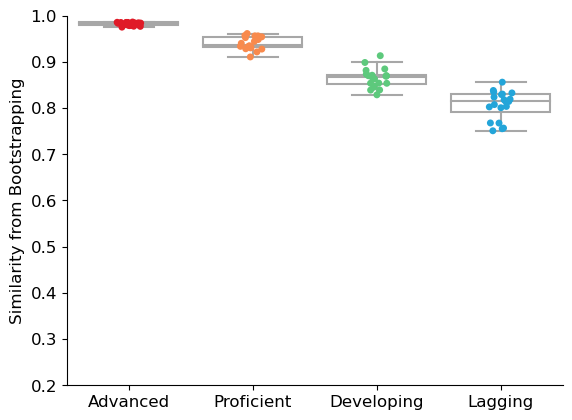

In [38]:
fig, ax=plt.subplots()
color={'Advanced':'#E01A27','Proficient':'#F88A4D','Developing':'#5DC97C','Lagging':'#23A5D9'}
order = ['Advanced','Proficient','Developing','Lagging']
sns.stripplot(x='st',y='simi',data=btsp_res,ax=ax, order=order, palette=color)
sns.boxplot(x='st',y='simi',data=btsp_res,
            boxprops={'facecolor':'none', 'edgecolor':'#A7A7A7'},
            medianprops={'color':'#A7A7A7'},
            whiskerprops={'color':'#A7A7A7'},
            capprops={'color':'#A7A7A7'},
            order=order,
            fliersize=0,
            ax=ax)
ax.set_ylabel("Similarity from Bootstrapping", fontsize=12)
ax.set_xlabel("")
ax.set_ylim(0.2,1)
ax.tick_params(axis='both', which='major', labelsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.savefig("../../data/dropbox/LaborDivision/figs/bootstrapping_pub_similarity_derived_cntry_dis.pdf",bbox_inches='tight')